# CNNs and RNNs: A Gentle Introduction

> Understand why architecture should reflect spatial or sequential structure.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Identify data layouts for images and sequences.
- Understand convolution, pooling, recurrence, and temporal order intuitively.
- Use a lightweight scikit-learn example to classify flattened image pixels as a baseline.

CNNs exploit local spatial patterns through shared filters. RNNs process sequences step by step and maintain a hidden state. Modern tasks often use transformers, but CNNs and recurrent models remain useful concepts and tools.

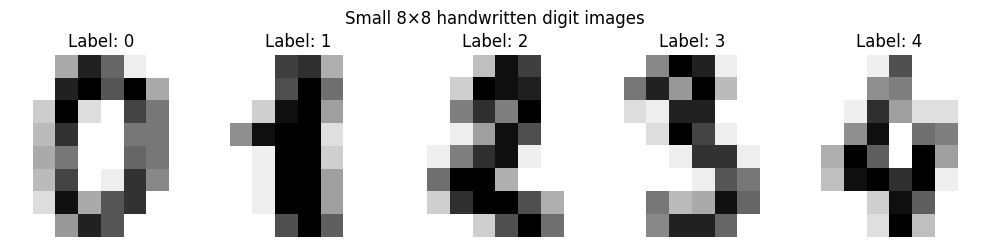

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
fig, axes = plt.subplots(1, 5, figsize=(10,2.5))
for ax, image, label in zip(axes, digits.images[:5], digits.target[:5]):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Small 8×8 handwritten digit images")
plt.tight_layout()

## Shape intuition
- Image batch: often `(batch, channels, height, width)` in PyTorch or `(batch, height, width, channels)` in TensorFlow by default.
- Text/token sequence: often `(batch, sequence_length, embedding_dim)` before architecture-specific projections.
- 1D temporal signals can use `(batch, channels, length)` for convolutional sequence models.

Always check framework conventions. A shape mismatch can look like a model problem while being only a data-layout problem.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
X = digits.data / 16.0
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
flat_baseline = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=400, early_stopping=True, random_state=42))
flat_baseline.fit(X_train, y_train)
print("Flattened-pixel MLP accuracy:", round(accuracy_score(y_test, flat_baseline.predict(X_test)),3))

Flattened-pixel MLP accuracy: 0.947


## Architecture concepts
- **Convolution:** a shared filter scans local neighborhoods; this creates translation-sensitive local features with fewer parameters than a fully connected layer.
- **Pooling / stride:** reduces spatial resolution and can add some tolerance to small shifts.
- **RNN / LSTM / GRU:** processes ordered inputs with a recurrent hidden state; sequential computation can limit parallelism.
- **Transformers:** use attention to mix information across tokens in parallel during training, with cost depending on sequence length and architecture.

Do not treat this overview as a substitute for hands-on image or sequence work. It is intended to orient you before the dedicated deep learning notebooks.

## Practice
Explain why shuffling individual time steps within a sequence usually destroys information. For images, list two ways a model might accidentally use background cues rather than the object of interest.